# All-Function Surrogate Diagnostics Through Week 5

Compare five GP kernels and a training-mean baseline across Functions 1-8. This extends Week 4 Notebook 05's shared-fold and historical-backtest design. Shuffled cross-validation measures reconstruction on the available observations; the rolling-origin backtest is the relevant test of future-week prediction because every fit excludes the week being predicted. At the configured settings, the two designs require 400 GP fits with 10 optimizer restarts each. This rerun uses a notebook-local **WhiteKernel noise-variance lower bound of `1e-10`** for every kernel and function; other bounds and shared defaults are unchanged. The notebook is read-only and writes no candidates or outcomes.

In [1]:
%matplotlib inline
from pathlib import Path

from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import KFold

from bayesian_bbo import CONFIG, FUNCTION_SPECS
from bayesian_bbo.history import load_weekly_history
from bayesian_bbo.kernels import make_comparison_kernels
from bayesian_bbo.validation import evaluate_kernel_splits
from bayesian_bbo.visualisation import plot_calibration

CURRENT_WEEK = 5
WEEKS = tuple(range(1, CURRENT_WEEK + 1))
FUNCTION_IDS = tuple(FUNCTION_SPECS)
N_SPLITS = 5
RANDOM_STATE = CONFIG['random_state']
N_RESTARTS = CONFIG['n_restarts_optimizer']
NOISE_MIN = 1e-10

data_candidates = [Path('../../data'), Path('data'), Path('../data')]
matches = [path.resolve() for path in data_candidates if (path / 'function_1').is_dir()]
if not matches:
    raise FileNotFoundError('Could not find the data directory from the notebook working directory.')
data_root = matches[0]
history = load_weekly_history(data_root, current_week=CURRENT_WEEK, function_ids=FUNCTION_IDS)
observations_by_function = history.observations
historical_results = history.records.loc[history.records.week.isin(WEEKS)].copy()
kernels_by_function = {
    function_id: make_comparison_kernels(
        observations.dimension, CONFIG['length_caps'][function_id],
    )
    for function_id, observations in observations_by_function.items()
}
for kernels in kernels_by_function.values():
    for kernel in kernels.values():
        kernel.set_params(k2__noise_level_bounds=(NOISE_MIN, kernel.k2.noise_level_bounds[1]))
KERNEL_NAMES = list(kernels_by_function[FUNCTION_IDS[0]]) + ['Training mean']
print(f'Data root: {data_root}')
print(f'Functions: {FUNCTION_IDS}; observations cutoff: week {CURRENT_WEEK}')
print(f'{N_SPLITS}-fold CV; {N_RESTARTS} optimizer restarts per GP fit')
print(f'WhiteKernel noise-variance lower bound: {NOISE_MIN:g}')
print(f'Kernels: {KERNEL_NAMES}')

Data root: /home/pabloncho/repositories/bayesian-bbo/data
Functions: (1, 2, 3, 4, 5, 6, 7, 8); observations cutoff: week 5
5-fold CV; 10 optimizer restarts per GP fit
WhiteKernel noise-variance lower bound: 1e-10
Kernels: ['Matérn 3/2', 'Matérn 5/2', 'RBF', 'Rational Quadratic', 'Exp-Sine-Squared', 'Training mean']


## 1. Saved-prediction residuals

These residuals use the historical means and standard deviations saved before each evaluation. They diagnose the model policy that actually generated the observations; they do not compare alternative kernels and are not recomputed under the new noise bound. Five sequential observations per function are too few for precise coverage estimates.

,observations,mean_z,rms_z,coverage_95,week5_z
function_id,,,,,
1,5,118.788,274.802,0.6,-0.031
2,5,-0.344,1.124,0.8,0.192
3,5,-0.699,1.179,1.0,-0.446
4,5,0.403,2.059,0.6,1.005
5,5,17.423,42.775,0.2,2.817
6,5,-0.872,1.423,0.8,-2.746
7,5,-0.554,5.187,0.2,-8.368
8,5,-0.580,1.305,1.0,-1.266


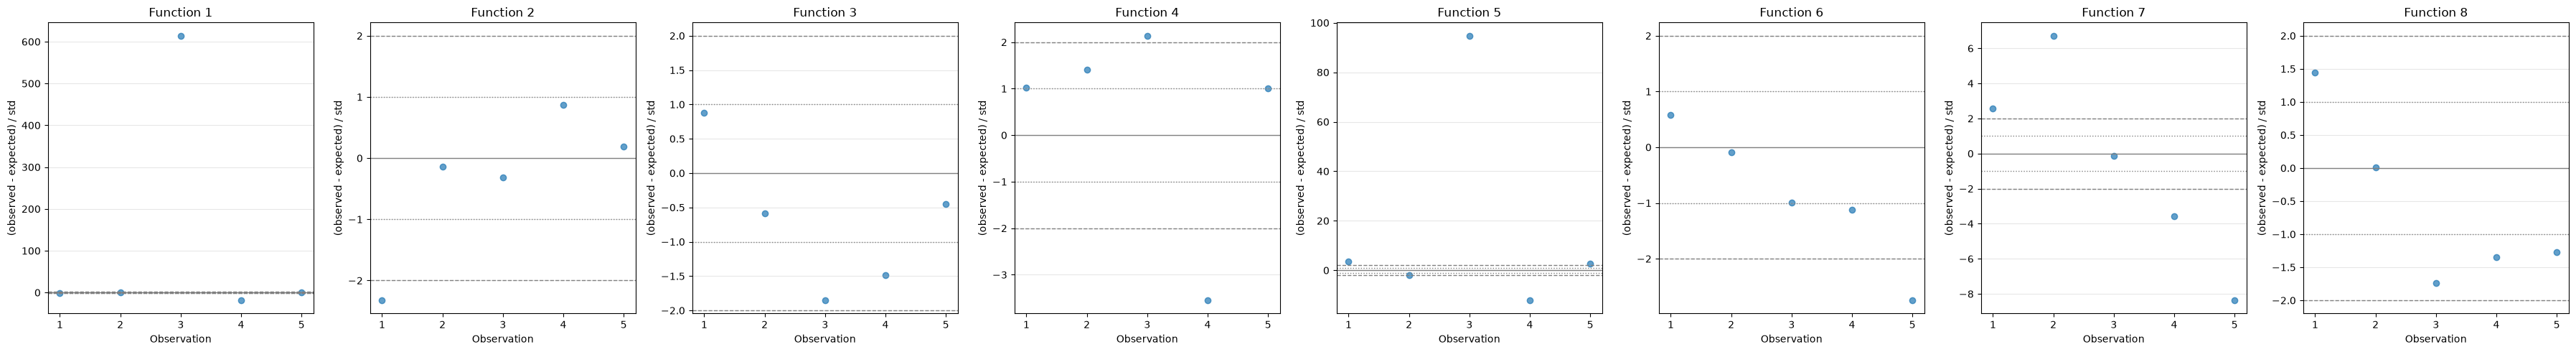

In [3]:
residuals = historical_results.groupby('function_id').residual.apply(list).to_dict()
residual_summary = historical_results.groupby('function_id').agg(
    observations=('residual', 'size'),
    mean_z=('residual', 'mean'),
    rms_z=('residual', lambda values: float(np.sqrt(np.mean(values**2)))),
    coverage_95=('residual', lambda values: float(np.mean(np.abs(values) <= 1.96))),
)
week5_residuals = historical_results.loc[historical_results.week == CURRENT_WEEK].set_index('function_id').residual
residual_summary['week5_z'] = week5_residuals.reindex(FUNCTION_IDS)
display(residual_summary.reindex(FUNCTION_IDS).round(3))
calibration_figure, calibration_axes = plot_calibration(residuals)
display(calibration_figure)
plt.close(calibration_figure)

## 2. Shared shuffled folds

For each function, the observations are randomly split into five folds. Each kernel is trained on four folds and scored on the same held-out fifth, so kernel comparisons are paired on identical test rows. Because weeks are shuffled, a held-out early-week point can be predicted using later-week observations in the training folds. This measures reconstruction/interpolation, not a forecast of the next week. Compare metrics within a function; output scales differ across functions.

In [4]:
def summarize_predictions(frame, groups):
    summary = frame.groupby(groups).agg(
        count=('actual', 'size'), MSE=('squared_error', 'mean'),
        MAE=('absolute_error', 'mean'), NLL=('nlpd', 'mean'),
        coverage_90=('covered_90', 'mean'), coverage_95=('covered_95', 'mean'),
        width_95=('width_95', 'mean'),
        worst_abs_z=('z', lambda values: values.abs().max()),
    )
    summary['RMSE'] = np.sqrt(summary.pop('MSE'))
    return summary

cv_frames = []
folds_by_function = {}
for function_id, observations in observations_by_function.items():
    folds = dict(enumerate(
        KFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE).split(observations.inputs),
        start=1,
    ))
    folds_by_function[function_id] = folds
    rows = evaluate_kernel_splits(
        observations, kernels_by_function[function_id], folds,
        random_state=RANDOM_STATE, n_restarts_optimizer=N_RESTARTS,
        normalize_y=CONFIG['normalize_y'],
    )
    rows.insert(0, 'function_id', function_id)
    cv_frames.append(rows)
cv_results = pd.concat(cv_frames, ignore_index=True)
cv_summary = summarize_predictions(cv_results, ['function_id', 'kernel'])
display(cv_summary.round(3))

/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 31.622776601683793. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 31.622776601683793. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 31.622776601683793. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__alpha is close to the specified upper bound 100000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 31.622776601683793. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 31.622776601683793. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


... (79 outputs left out)

/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 5 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 7 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-10. Decreasing the bound and calling fit again may find a better val

/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 7 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-10. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-10. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


count       MAE        NLL  coverage_90  \
function_id kernel                                                        
1           Exp-Sine-Squared       15     0.000   4977.358        0.933   
            Matérn 3/2             15     0.000  20411.467        0.800   
            Matérn 5/2             15     0.000  17710.396        0.800   
            RBF                    15     0.000  20660.663        0.800   
            Rational Quadratic     15     0.000   4976.982        0.933   
            Training mean          15     0.000   5056.539        0.933   
2           Exp-Sine-Squared       15     0.250      0.712        0.733   
            Matérn 3/2             15     0.085     -0.830        0.733   
            Matérn 5/2             15     0.077     -0.857        0.800   
            RBF                    15     0.074     -0.341        0.667   
            Rational Quadratic     15     0.203      0.315        0.867   
            Training mean          15     0.247      0.200        0.867   
3           Exp-Sine-Squared       20     0.048      0.151        0.950   
            Matérn 3/2             20     0.047      0.595        0.750   
            Matérn 5/2             20     0.048      1.050        0.700   
            RBF                    20     0.041      4.101        0.750   
            Rational Quadratic     20     0.051     -0.071        0.950   
            Training mean          20     0.048      0.099        0.950   
4           Exp-Sine-Squared       35     7.003      3.625        0.857   
            Matérn 3/2             35     1.254      1.971        0.943   
            Matérn 5/2             35     1.346      3.039        0.914   
            RBF                    35     3.020      5.075        0.657   
            Rational Quadratic     35     1.054      5.268        0.943   
            Training mean          35     6.921      3.631        0.829   
5           Exp-Sine-Squared       25  1083.919      9.499        0.920   
            Matérn 3/2             25   741.558    149.381        0.600   
            Matérn 5/2             25   634.727     51.495        0.600   
            RBF                    25   667.455    103.497        0.480   
            Rational Quadratic     25   333.483      7.409        0.920   
            Training mean          25  1078.789      9.478        0.920   
6           Exp-Sine-Squared       25     0.444      0.894        0.920   
            Matérn 3/2             25     0.261      0.288        0.800   
            Matérn 5/2             25     0.289      0.345        0.840   
            RBF                    25     0.287      0.536        0.720   
            Rational Quadratic     25     0.191     -0.125        0.840   
            Training mean          25     0.443      0.893        0.920   
7           Exp-Sine-Squared       35     0.525      1.101        0.829   
            Matérn 3/2             35     0.334      2.532        0.743   
            Matérn 5/2             35     0.339      4.308        0.743   
            RBF                    35     0.349      7.337        0.771   
            Rational Quadratic     35     0.312      1.049        0.914   
            Training mean          35     0.507      1.043        0.886   
8           Exp-Sine-Squared       45     0.996      1.875        0.822   
            Matérn 3/2             45     0.118     -0.583        0.911   
            Matérn 5/2             45     0.097     -0.701        0.867   
            RBF                    45     0.141      0.011        0.689   
            Rational Quadratic     45     0.148     -0.270        0.956   
            Training mean          45     0.970      1.587        0.867   

                                coverage_95  width_95  worst_abs_z      RMSE  
function_id kernel                                                            
1           Exp-Sine-Squared          0.933     0.005      386.680     0.001  
            Matérn 3/2                0.800 

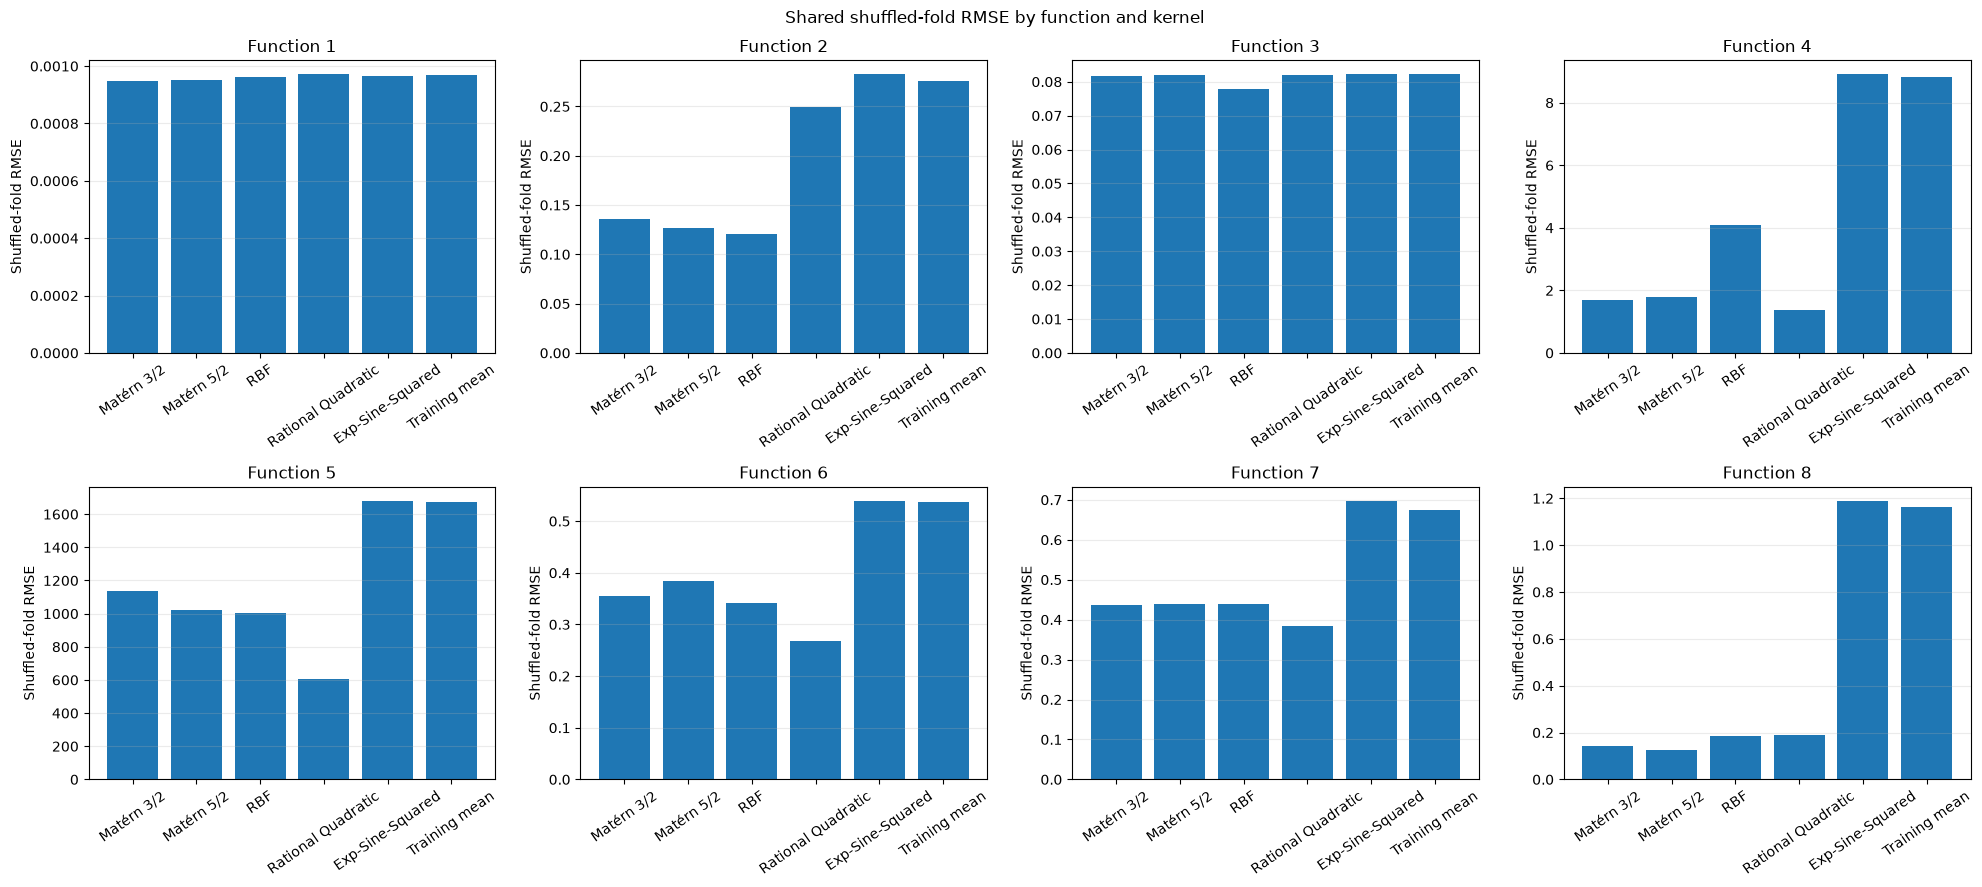

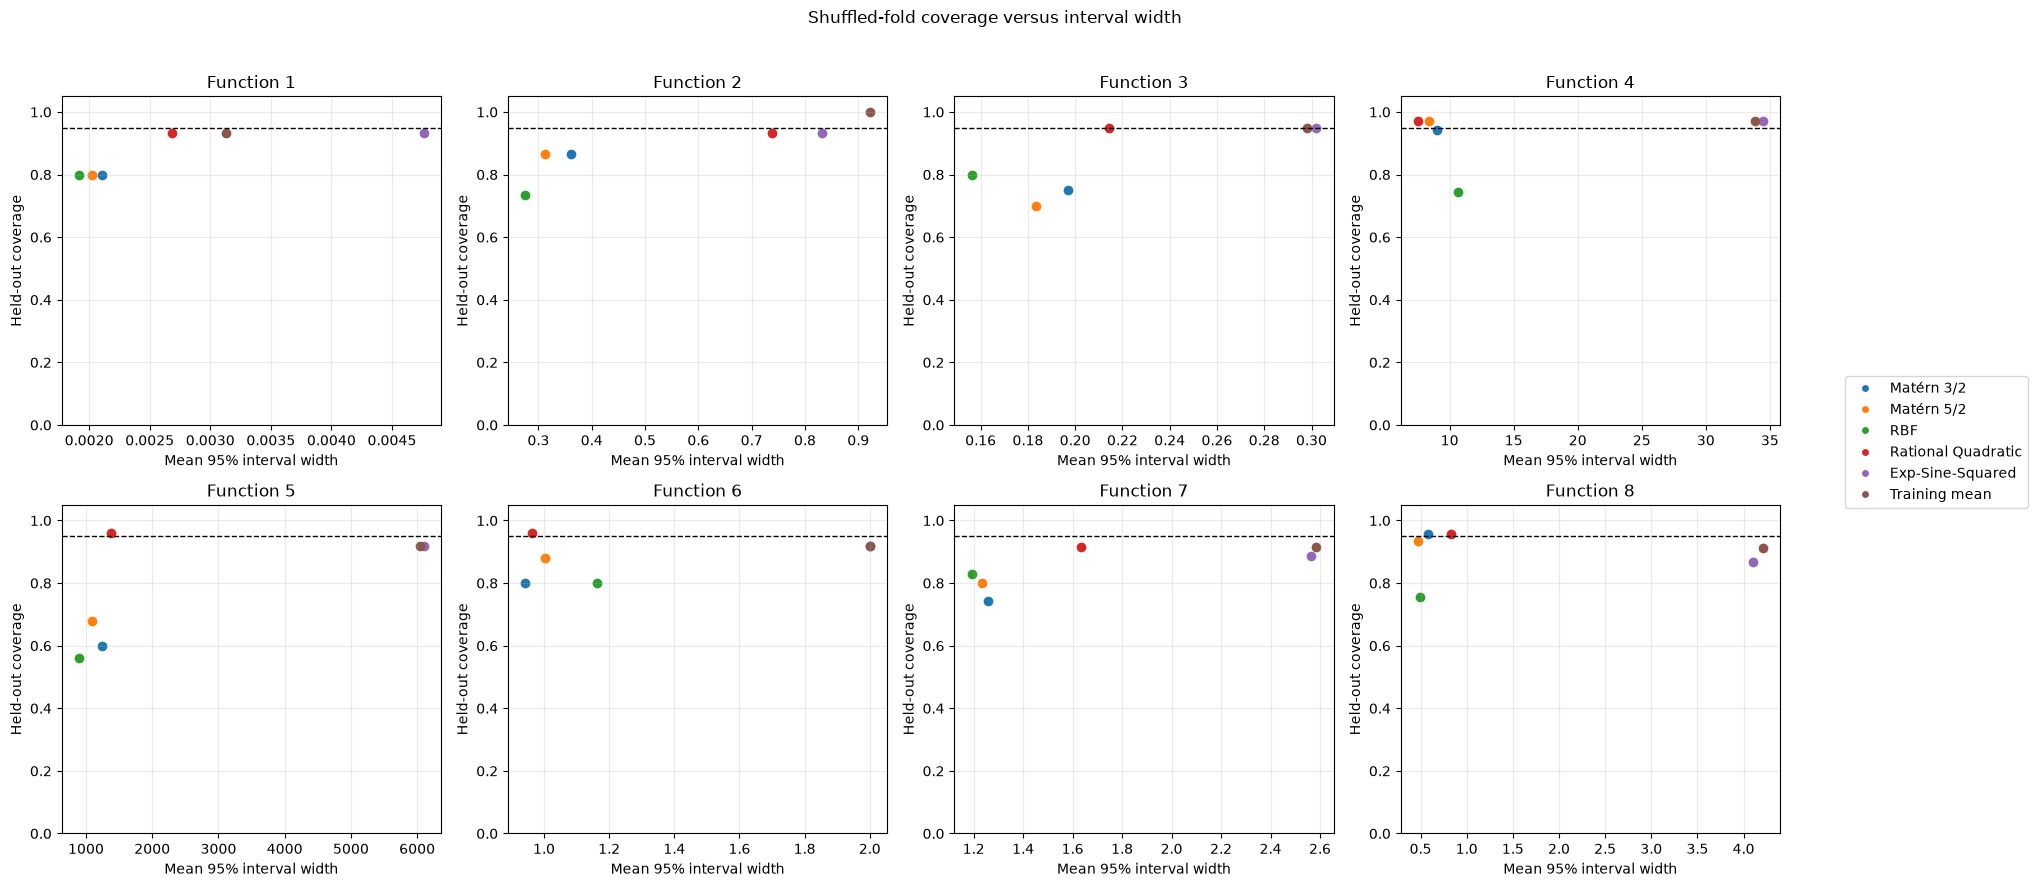

In [5]:
from matplotlib.lines import Line2D

cv_rmse_figure, cv_rmse_axes = plt.subplots(2, 4, figsize=(20, 9), squeeze=False)
for function_id, ax in zip(FUNCTION_IDS, cv_rmse_axes.flat):
    rows = cv_summary.xs(function_id, level='function_id').reindex(KERNEL_NAMES)
    ax.bar(np.arange(len(rows)), rows.RMSE, color='C0')
    ax.set(
        title=f'Function {function_id}', ylabel='Shuffled-fold RMSE',
        xticks=np.arange(len(rows)), xticklabels=rows.index,
    )
    ax.tick_params(axis='x', labelrotation=35)
    ax.grid(axis='y', alpha=0.25)
cv_rmse_figure.suptitle('Shared shuffled-fold RMSE by function and kernel')
cv_rmse_figure.tight_layout()
display(cv_rmse_figure)
plt.close(cv_rmse_figure)

kernel_colors = {name: f'C{index}' for index, name in enumerate(KERNEL_NAMES)}
cv_interval_figure, cv_interval_axes = plt.subplots(2, 4, figsize=(20, 9), squeeze=False)
for function_id, ax in zip(FUNCTION_IDS, cv_interval_axes.flat):
    rows = cv_summary.xs(function_id, level='function_id').reindex(KERNEL_NAMES)
    for kernel_name, row in rows.iterrows():
        ax.scatter(row.width_95, row.coverage_95, color=kernel_colors[kernel_name])
    ax.axhline(0.95, color='black', linestyle='--', linewidth=1)
    ax.set(
        title=f'Function {function_id}', xlabel='Mean 95% interval width',
        ylabel='Held-out coverage', ylim=(0, 1.05),
    )
    ax.grid(alpha=0.25)
legend_handles = [
    Line2D([0], [0], marker='o', color='w', markerfacecolor=kernel_colors[name], label=name)
    for name in KERNEL_NAMES
]
cv_interval_figure.suptitle('Shuffled-fold coverage versus interval width')
cv_interval_figure.legend(handles=legend_handles, loc='center right', bbox_to_anchor=(1.02, 0.5))
cv_interval_figure.tight_layout(rect=(0, 0, 0.90, 0.96))
display(cv_interval_figure)
plt.close(cv_interval_figure)

## 3. Rolling-origin next-week backtest

For each evaluated week $w$, train only on rows with week less than $w$ and predict the actual input from week $w$. This matches the information available before each evaluation. It tests predictive behavior at the historical selected inputs, not which kernel would have selected a better input. Check the training cutoff assertion below before interpreting scores.

In [6]:
backtest_frames = []
splits_by_function = {}
for function_id, observations in observations_by_function.items():
    splits = {
        week: (np.flatnonzero(observations.weeks < week), np.flatnonzero(observations.weeks == week))
        for week in WEEKS
    }
    splits_by_function[function_id] = splits
    rows = evaluate_kernel_splits(
        observations, kernels_by_function[function_id], splits,
        random_state=RANDOM_STATE, n_restarts_optimizer=N_RESTARTS,
        normalize_y=CONFIG['normalize_y'],
    )
    rows.insert(0, 'function_id', function_id)
    backtest_frames.append(rows)
backtest = pd.concat(backtest_frames, ignore_index=True)
assert (backtest.training_max_week < backtest.week).all()
assert (backtest['split'] == backtest.week).all()
backtest_summary = summarize_predictions(backtest, ['function_id', 'kernel'])
display(backtest_summary.round(3))

/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 31.622776601683793. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 31.622776601683793. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 31.622776601683793. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__alpha is close to the specified upper bound 100000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified lower bound 0.001. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 31.622776601683793. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 31.622776601683793. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 31.622776601683793. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified upper bound 31.622776601683793. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


... (103 outputs left out)

/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 7 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-10. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 7 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-10. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 5 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 7 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-10. Decreasing the bound and calling fit again may find a better val

count       MAE         NLL  coverage_90  \
function_id kernel                                                         
1           Exp-Sine-Squared        5     0.000      -5.801          1.0   
            Matérn 3/2              5     0.001   37766.783          0.6   
            Matérn 5/2              5     0.001   67880.427          0.6   
            RBF                     5     0.001  119841.959          0.6   
            Rational Quadratic      5     0.000      -6.200          1.0   
            Training mean           5     0.000      -5.945          1.0   
2           Exp-Sine-Squared        5     0.241       0.197          0.8   
            Matérn 3/2              5     0.061      -1.637          1.0   
            Matérn 5/2              5     0.062      -1.683          1.0   
            RBF                     5     0.050      -1.639          1.0   
            Rational Quadratic      5     0.254       0.876          0.6   
            Training mean           5     0.241       0.201          0.8   
3           Exp-Sine-Squared        5     0.051      -1.295          1.0   
            Matérn 3/2              5     0.062      -1.172          0.8   
            Matérn 5/2              5     0.062      -1.073          0.6   
            RBF                     5     0.038      -1.591          0.8   
            Rational Quadratic      5     0.030      -1.697          1.0   
            Training mean           5     0.051      -1.305          1.0   
4           Exp-Sine-Squared        5    15.335       4.973          0.0   
            Matérn 3/2              5     1.306       2.733          0.6   
            Matérn 5/2              5     1.222       8.627          0.4   
            RBF                     5     1.061       4.817          0.4   
            Rational Quadratic      5     1.104       5.999          0.2   
            Training mean           5    15.334       4.961          0.0   
5           Exp-Sine-Squared        5  2902.940      22.407          0.0   
            Matérn 3/2              5  1625.652     920.436          0.2   
            Matérn 5/2              5  1554.434     758.190          0.2   
            RBF                     5  1856.479     315.049          0.2   
            Rational Quadratic      5   962.591      22.553          0.4   
            Training mean           5  2916.725      23.481          0.0   
6           Exp-Sine-Squared        5     0.723       1.291          0.6   
            Matérn 3/2              5     0.184       0.392          0.6   
            Matérn 5/2              5     0.187       0.876          0.6   
            RBF                     5     0.245       1.395          0.6   
            Rational Quadratic      5     0.132      -0.614          1.0   
            Training mean           5     0.723       1.392          0.6   
7           Exp-Sine-Squared        5     1.548       8.608          0.0   
            Matérn 3/2              5     0.529      11.906          0.4   
            Matérn 5/2              5     0.551      20.269          0.4   
            RBF                     5     0.698      16.865          0.4   
            Rational Quadratic      5     0.773       5.756          0.2   
            Training mean           5     1.549       7.571          0.0   
8           Exp-Sine-Squared        5     1.868       2.686          0.0   
            Matérn 3/2              5     0.128      -0.645          0.8   
            Matérn 5/2              5     0.118      -0.561          0.6   
            RBF                     5     0.113      -0.199          0.8   
            Rational Quadratic      5     0.061      -0.830          1.0   
            Training mean           5     1.857       2.648          0.0   

                                coverage_95  width_95  worst_abs_z      RMSE  
function_id kernel                                                            
1           Exp-Sine-Squared            1.0     0.005        0.333     0.

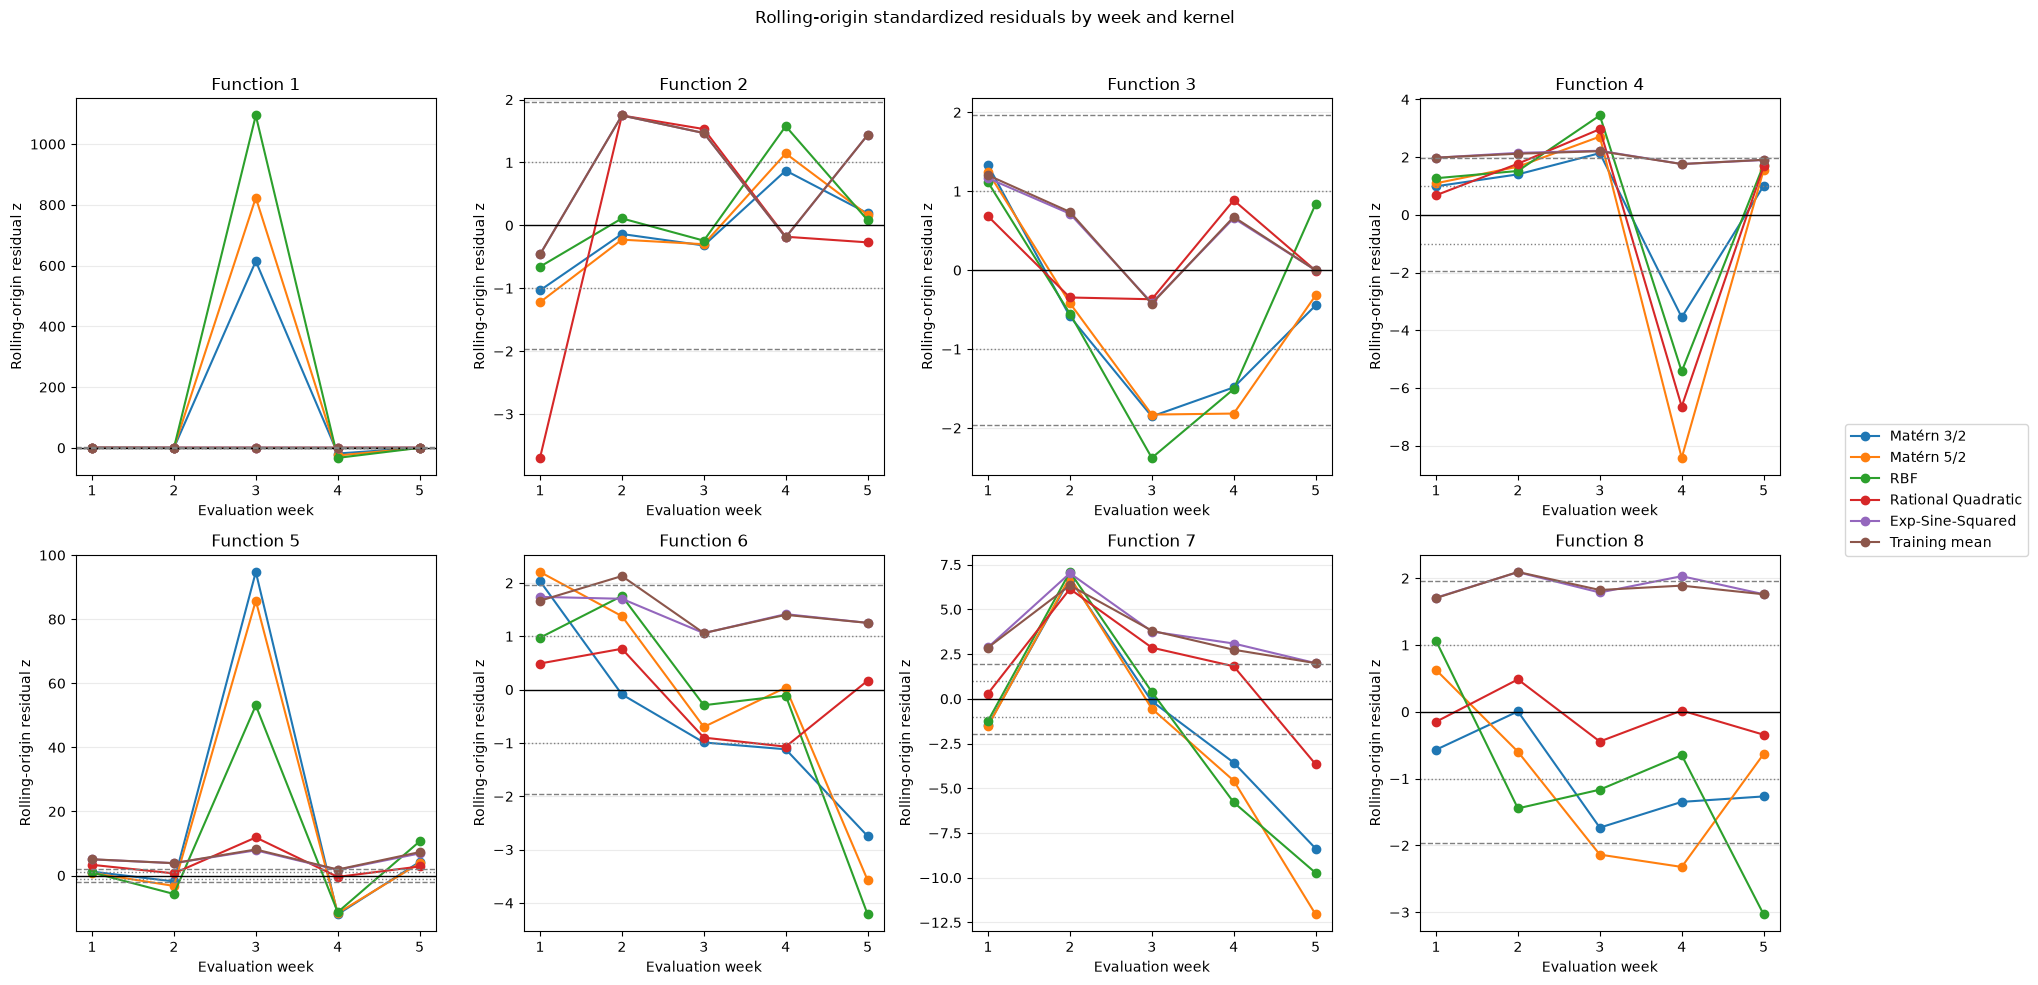

In [7]:
from matplotlib.lines import Line2D

backtest_residual_figure, backtest_residual_axes = plt.subplots(2, 4, figsize=(20, 10), squeeze=False)
backtest_kernel_colors = {name: f'C{index}' for index, name in enumerate(KERNEL_NAMES)}
for function_id, ax in zip(FUNCTION_IDS, backtest_residual_axes.flat):
    function_rows = backtest.loc[backtest.function_id == function_id]
    for kernel_name in KERNEL_NAMES:
        rows = function_rows.loc[function_rows.kernel == kernel_name].sort_values('week')
        ax.plot(
            rows.week, rows.z, marker='o', color=backtest_kernel_colors[kernel_name],
        )
    ax.axhline(0, color='black', linewidth=1)
    for level, style in ((1, ':'), (-1, ':'), (1.96, '--'), (-1.96, '--')):
        ax.axhline(level, color='gray', linestyle=style, linewidth=1)
    ax.set(
        title=f'Function {function_id}', xlabel='Evaluation week',
        ylabel='Rolling-origin residual z', xticks=list(WEEKS),
    )
    ax.grid(axis='y', alpha=0.25)
residual_legend = [
    Line2D([0], [0], marker='o', color=backtest_kernel_colors[name], label=name)
    for name in KERNEL_NAMES
]
backtest_residual_figure.suptitle('Rolling-origin standardized residuals by week and kernel')
backtest_residual_figure.legend(
    handles=residual_legend, loc='center right', bbox_to_anchor=(1.02, 0.5),
)
backtest_residual_figure.tight_layout(rect=(0, 0, 0.90, 0.96))
display(backtest_residual_figure)
plt.close(backtest_residual_figure)

## 4. Compare errors and interval behavior

Lower RMSE, MAE, and NLL are better. Coverage should be read alongside interval width: very wide intervals can cover observations without being useful. The Week 5 table isolates the latest predictions for all kernels. The final focused table shows the Week 5 mean/std and rolling metrics for Matérn 3/2 and RQ on F6/F7, with the tentative recommendation marked explicitly. Kernel rankings are descriptive, not automatic selection rules.

,function_id,kernel,actual,mean,std,z,nlpd,covered_95,width_95
28,1,Rational Quadratic,0.000,-0.000,0.000,0.513,-7.300,True,0.001
27,1,RBF,0.000,0.000,0.000,-0.062,-7.290,True,0.001
26,1,Matérn 5/2,0.000,0.000,0.000,-0.049,-7.042,True,0.001
25,1,Matérn 3/2,0.000,0.000,0.000,-0.031,-6.864,True,0.002
24,1,Training mean,0.000,-0.000,0.001,0.286,-6.022,True,0.004
29,1,Exp-Sine-Squared,0.000,-0.000,0.001,0.277,-5.991,True,0.004
57,2,RBF,0.611,0.609,0.023,0.084,-2.834,True,0.092
56,2,Matérn 5/2,0.611,0.606,0.025,0.167,-2.749,True,0.099
55,2,Matérn 3/2,0.611,0.605,0.027,0.192,-2.678,True,0.105
58,2,Rational Quadratic,0.611,0.620,0.036,-0.270,-2.370,True,0.141


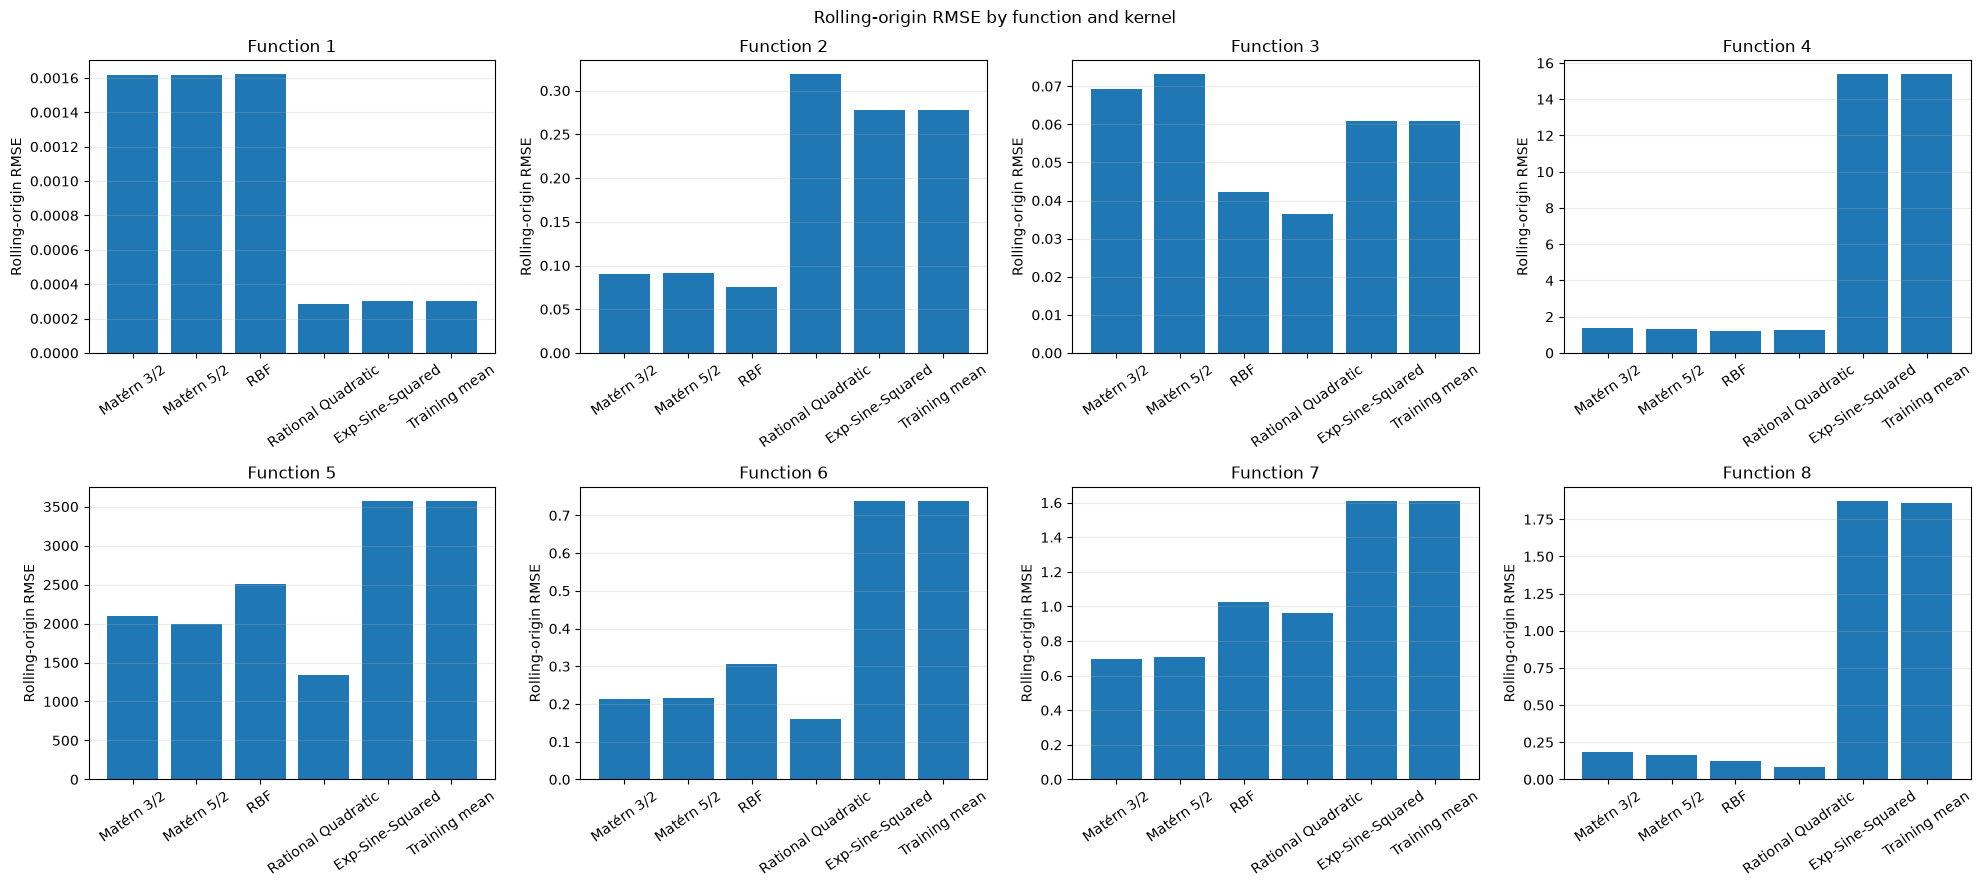

RMSE       MAE         NLL  coverage_95  \
function_id kernel                                                            
1           Exp-Sine-Squared       0.000     0.000      -5.801          1.0   
            Matérn 3/2             0.002     0.001   37766.783          0.6   
            Matérn 5/2             0.002     0.001   67880.427          0.6   
            RBF                    0.002     0.001  119841.959          0.6   
            Rational Quadratic     0.000     0.000      -6.200          1.0   
            Training mean          0.000     0.000      -5.945          1.0   
2           Exp-Sine-Squared       0.278     0.241       0.197          1.0   
            Matérn 3/2             0.090     0.061      -1.637          1.0   
            Matérn 5/2             0.091     0.062      -1.683          1.0   
            RBF                    0.075     0.050      -1.639          1.0   
            Rational Quadratic     0.319     0.254       0.876          0.8   
            Training mean          0.278     0.241       0.201          1.0   
3           Exp-Sine-Squared       0.061     0.051      -1.295          1.0   
            Matérn 3/2             0.069     0.062      -1.172          1.0   
            Matérn 5/2             0.073     0.062      -1.073          1.0   
            RBF                    0.042     0.038      -1.591          0.8   
            Rational Quadratic     0.036     0.030      -1.697          1.0   
            Training mean          0.061     0.051      -1.305          1.0   
4           Exp-Sine-Squared      15.376    15.335       4.973          0.4   
            Matérn 3/2             1.401     1.306       2.733          0.6   
            Matérn 5/2             1.340     1.222       8.627          0.6   
            RBF                    1.197     1.061       4.817          0.6   
            Rational Quadratic     1.245     1.104       5.999          0.6   
            Training mean         15.375    15.334       4.961          0.4   
5           Exp-Sine-Squared    3572.883  2902.940      22.407          0.2   
            Matérn 3/2          2103.049  1625.652     920.436          0.4   
            Matérn 5/2          1989.725  1554.434     758.190          0.2   
            RBF                 2505.811  1856.479     315.049          0.2   
            Rational Quadratic  1337.802   962.591      22.553          0.4   
            Training mean       3575.354  2916.725      23.481          0.2   
6           Exp-Sine-Squared       0.739     0.723       1.291          1.0   
            Matérn 3/2             0.213     0.184       0.392          0.6   
            Matérn 5/2             0.216     0.187       0.876          0.6   
            RBF                    0.307     0.245       1.395          0.8   
            Rational Quadratic     0.161     0.132      -0.614          1.0   
            Training mean          0.739     0.723       1.392          0.8   
7           Exp-Sine-Squared       1.610     1.548       8.608          0.0   
            Matérn 3/2             0.699     0.529      11.906          0.4   
            Matérn 5/2             0.706     0.551      20.269          0.4   
            RBF                    1.024     0.698      16.865          0.4   
            Rational Quadratic     0.961     0.773       5.756          0.4   
            Training mean          1.611     1.549       7.571          0.0   
8           Exp-Sine-Squared       1.874     1.868       2.686          0.6   
            Matérn 3/2             0.183     0.128      -0.645          1.0   
            Matérn 5/2             0.166     0.118      -0.561          0.6   
            RBF                    0.123     0.113      -0.199          0.8   
            Rational Quadratic     0.081     0.061      -0.830          1.0   
            Training mean          1.862     1.857       2.648          0.8   

                                width_95  RMSE_shuffled  NLL_shuffled  \
function_id 

Use rolling-origin results for future-week prediction; shuffled-fold results are reconstruction diagnostics.
F6/F7 candidate-kernel values at the same evaluated Week 5 inputs:


,function_id,kernel,decision,week5_actual,week5_mean,week5_std,week5_z,week5_covered_95,rolling_RMSE,rolling_NLL,rolling_coverage_95,rolling_width_95
0,6,Matérn 3/2,Current baseline,-0.724,-0.434,0.105,-2.746,False,0.213,0.392,0.6,0.667
1,6,Rational Quadratic,Recommended prospective test,-0.724,-0.755,0.188,0.168,True,0.161,-0.614,1.0,0.721
2,7,Matérn 3/2,Reference only; not validated,1.687,2.483,0.095,-8.368,False,0.699,11.906,0.4,0.544
3,7,Rational Quadratic,Alternative; no clear winner,1.687,2.418,0.200,-3.657,False,0.961,5.756,0.4,0.964


In [8]:
week5_backtest = backtest.loc[
    backtest.week == CURRENT_WEEK,
    ['function_id', 'kernel', 'actual', 'mean', 'std', 'z', 'nlpd', 'covered_95', 'width_95'],
].sort_values(['function_id', 'nlpd'])
display(week5_backtest.round(3))

fig, axes = plt.subplots(2, 4, figsize=(20, 9), squeeze=False)
for function_id, ax in zip(FUNCTION_IDS, axes.flat):
    rows = backtest_summary.xs(function_id, level='function_id').reindex(KERNEL_NAMES)
    ax.bar(np.arange(len(rows)), rows.RMSE, color='C0')
    ax.set(
        title=f'Function {function_id}', ylabel='Rolling-origin RMSE',
        xticks=np.arange(len(rows)), xticklabels=rows.index,
    )
    ax.tick_params(axis='x', labelrotation=35)
    ax.grid(axis='y', alpha=0.25)
fig.suptitle('Rolling-origin RMSE by function and kernel')
fig.tight_layout()
display(fig)
plt.close(fig)

decision_view = backtest_summary[['RMSE', 'MAE', 'NLL', 'coverage_95', 'width_95']].join(
    cv_summary[['RMSE', 'NLL', 'coverage_95']].add_suffix('_shuffled'),
)
display(decision_view.round(3))
print('Use rolling-origin results for future-week prediction; shuffled-fold results are reconstruction diagnostics.')

recommendation_plan = {
    (6, 'Matérn 3/2'): 'Current baseline',
    (6, 'Rational Quadratic'): 'Recommended prospective test',
    (7, 'Matérn 3/2'): 'Reference only; not validated',
    (7, 'Rational Quadratic'): 'Alternative; no clear winner',
}
recommendation_rows = []
for (function_id, kernel_name), decision in recommendation_plan.items():
    latest = week5_backtest.loc[
        (week5_backtest.function_id == function_id)
        & (week5_backtest.kernel == kernel_name)
    ].iloc[0]
    rolling = backtest_summary.loc[(function_id, kernel_name)]
    recommendation_rows.append({
        'function_id': function_id,
        'kernel': kernel_name,
        'decision': decision,
        'week5_actual': latest.actual,
        'week5_mean': latest['mean'],
        'week5_std': latest['std'],
        'week5_z': latest.z,
        'week5_covered_95': latest.covered_95,
        'rolling_RMSE': rolling.RMSE,
        'rolling_NLL': rolling.NLL,
        'rolling_coverage_95': rolling.coverage_95,
        'rolling_width_95': rolling.width_95,
    })
recommendation_table = pd.DataFrame(recommendation_rows)
if len(recommendation_table) != 4:
    raise ValueError('Expected Week 5 prediction values for both kernels on F6 and F7.')
print('F6/F7 candidate-kernel values at the same evaluated Week 5 inputs:')
display(recommendation_table.round(3))

## Interpretation limits

Each function has only five sequential held-out evaluations. These are adaptively selected points, not independent random test samples, and many GP fits may emit convergence warnings at parameter bounds. A low score or high coverage on this small history is evidence to investigate, not proof that a kernel is calibrated or globally optimal. Prioritize F6/F7's rolling-origin residuals, but retain per-function decisions rather than pooling raw output errors across scales.

## Historical provisional kernel recommendations for Week 6 (noise floor `1e-8`)

**Historical analysis record:** this static table and its comments are retained from the earlier `1e-8` noise-floor run. They are not the results of the current `1e-10` rerun. Use the freshly executed tables and plots above for current scores; the existing recommendation labels remain provisional rather than being selected automatically.

The Week 5 predictions below are evaluated at the same historical input for every kernel, using only observations through Week 4. The actual output is therefore shared; only each kernel's mean and uncertainty differ. Rolling metrics summarize five sequential predictions per function. Treat "test" as a prospective trial, not proof of a generally superior kernel.

| Function | Week 6 kernel action | Week 5 actual | Week 5 mean +/- std (z) | Rolling RMSE | 95% coverage | Comment |
| --- | --- | ---: | --- | ---: | ---: | --- |
| F1 | Test Rational Quadratic | 0.000006 | approximately 0 +/- 0 (0.51) | approximately 0 | 5/5 | RQ vs Matérn 3/2: both have tiny raw errors on F1's scale, but RQ covered 5/5 rolling points vs 3/5 for Matérn 3/2. Treat as a calibration test, not a clear accuracy win. |
| F2 | Test RBF | 0.610531 | 0.609 +/- 0.023 (0.08) | 0.075 | 5/5 | RBF vs Matérn 3/2 and 5/2: lowest rolling RMSE/NLL (0.075 vs 0.096 and 0.091); all covered 5/5. RQ was worse on RMSE and covered 4/5. |
| F3 | Test Rational Quadratic | -0.096282 | -0.096 +/- 0.060 (-0.01) | 0.036 | 5/5 | RQ vs Matérn 3/2 and RBF: lowest rolling RMSE (0.036 vs 0.069 and 0.048) and NLL (-1.697 vs -1.172 and -1.372); covered 5/5. |
| F4 | Keep Matérn 3/2 | 0.582951 | -0.194 +/- 0.774 (1.00) | 1.401 | 3/5 | RBF/RQ vs Matérn 3/2: lower rolling RMSE (1.197/1.245 vs 1.401), but Matérn 3/2 had better NLL (2.733 vs 4.817/5.999); all covered 3/5. No decisive switch. |
| F5 | Keep Rational Quadratic | 7156.856542 | 5312.778 +/- 654.554 (2.82) | 1343.408 | 2/5 | RQ vs Matérn 3/2: lower rolling RMSE (1343 vs 2103) and NLL (22.7 vs 920.4), but both covered only 2/5; RQ also missed Week 5. Keep RQ provisionally; calibration remains poor. |
| F6 | Test Rational Quadratic | -0.723566 | -0.755 +/- 0.188 (0.17) | 0.161 | 5/5 | RQ vs Matérn 3/2: lower rolling RMSE (0.161 vs 0.213), lower NLL (-0.613 vs 0.392), and coverage 5/5 vs 3/5. Strongest switch candidate; test prospectively. |
| F7 | Keep Matérn 3/2 as reference | 1.687241 | 2.483 +/- 0.095 (-8.37) | 0.699 | 2/5 | Matérn 3/2 vs RQ: Matérn has lower RMSE (0.699 vs 0.961); RQ has lower NLL (5.756 vs 11.906); both cover 2/5. Mixed evidence, no switch yet. |
| F8 | Test Rational Quadratic | 9.854370 | 9.893 +/- 0.113 (-0.34) | 0.081 | 5/5 | RQ vs Matérn 3/2: lower rolling RMSE (0.081 vs 0.182), lower NLL (-0.830 vs -0.653), and both covered 5/5. Shuffled CV favored Matérn 3/2, so treat RQ as a prospective test. |

The F1 prediction is rounded near zero; use its standardized residual and interval coverage rather than displayed decimal precision. A lower rolling RMSE or better coverage here is not a guarantee of higher optimization success: the kernels predict the already-selected Week 5 inputs, and only five sequential points are available per function.